In [ ]:
# Requiere instalación previa en Colab:
# !pip install cudf-cu12 cuml-cu12 cugraph-cu12 --extra-index-url=https://pypi.nvidia.com

import numpy as np
import time
from cuml.cluster import KMeans as GPU_KMeans
from sklearn.cluster import KMeans as CPU_KMeans

# Matriz de 5 millones de registros
X_masivo = np.random.rand(5000000, 2).astype('float32')

# 1. CPU Clásico
t0 = time.time()
cpu_model = CPU_KMeans(n_clusters=5, n_init=1).fit(X_masivo)
print(f"🐢 Tiempo CPU: {time.time() - t0:.2f} seg") # Tomará varios minutos

# 2. GPU con CUDA (cuML)
t0 = time.time()
gpu_model = GPU_KMeans(n_clusters=5).fit(X_masivo)
print(f"🚀 Tiempo GPU: {time.time() - t0:.2f} seg") # Fracciones de segundo

In [5]:

import numpy as np
from sklearn.cluster import KMeans, MiniBatchKMeans
import time

X_masivo = np.random.rand(5000000, 2).astype('float32')
# 1. Fuerza Bruta Local
t0 = time.time()
KMeans(n_clusters=5, n_init=1).fit(X_masivo)
print(f"🐢 K-Means Clásico: {time.time() - t0:.2f} seg")

# 2. Optimización Algorítmica (Muestreo)
t0 = time.time()
MiniBatchKMeans(n_clusters=5, batch_size=10000).fit(X_masivo)
print(f"⚡ Mini-Batch K-Means: {time.time() - t0:.2f} seg") 

🐢 K-Means Clásico: 4.94 seg
⚡ Mini-Batch K-Means: 54.50 seg


In [3]:
import random
import math

def generar_equipos(lista_alumnos, group_size = 5):
    alumnos_mezclados = lista_alumnos[:]
    random.shuffle(alumnos_mezclados)
    
    n = len(alumnos_mezclados)
    if n == 0:
        return []
        
    num_grupos = math.ceil(n / group_size)
    
    tamanos_grupos = [n // num_grupos + (1 if i < n % num_grupos else 0) for i in range(num_grupos)]
    
    equipos = []
    indice = 0
    
    for tamano in tamanos_grupos:
        equipos.append(alumnos_mezclados[indice:indice + tamano])
        indice += tamano
        
    return equipos
#
alumnos = ["Linette","Angela", "Rogelio", "Juan Pablo", "Octavio", "Cristobal",
"Ramiro", "Diego Angel", "Emiliano", "Carlos Miguel",
"Andrea", "Rhamses", "Mayrin", "Christopher", "Kamila","Andres", "Diego Torres",
"Raul", "Ximena", "Luis", "Diego Lopez", "Juan Manuel","Eric"]
equipos_formados = generar_equipos(alumnos,2)

for i, equipo in enumerate(equipos_formados, 1):
    print(f"Equipo {i} ({len(equipo)} integrantes): {', '.join(equipo)}")

Equipo 1 (2 integrantes): Carlos Miguel, Mayrin
Equipo 2 (2 integrantes): Andrea, Cristobal
Equipo 3 (2 integrantes): Juan Manuel, Kamila
Equipo 4 (2 integrantes): Juan Pablo, Ramiro
Equipo 5 (2 integrantes): Eric, Raul
Equipo 6 (2 integrantes): Emiliano, Andres
Equipo 7 (2 integrantes): Octavio, Ximena
Equipo 8 (2 integrantes): Luis, Linette
Equipo 9 (2 integrantes): Diego Torres, Diego Lopez
Equipo 10 (2 integrantes): Christopher, Angela
Equipo 11 (2 integrantes): Diego Angel, Rhamses
Equipo 12 (1 integrantes): Rogelio


In [4]:
import numpy as np
import matplotlib.pyplot as plt

class KMeansMatematico:
    def __init__(self, k:int=3, n_iter:int=100):
        self.iterations = n_iter
        self.k = k
        self.labels = None
        self.centroids = None

    def euclidean_distance(self, x:np.array, mu:np.array):
        return np.linalg.norm(x[:, np.newaxis] - mu, 2, axis=2)

    def fit(self, X:np.array):
        # Obtenemos las dimensiones del dataset
        n_muestras, n_features = X.shape

        # Creamos posiciones aleatorias
        random_samples = np.random.choice(n_muestras, self.k, replace=False)
        self.centroids = X[random_samples]

        for i in range(self.iterations):
            distances = self.euclidean_distance(X, self.centroids)

            self.labels = np.argmin(distances, axis=1)

            centroids_old = self.centroids.copy()

            for j in range(self.k):
                cluster_points = X[self.labels == j]
                if len(cluster_points) > 0:
                    self.centroids[j] = np.mean(cluster_points, axis=0)

            if np.all(centroids_old== self.centroids):
                print(f"✅ Convergencia alcanzada en la iteración {i+1}.")
                break

        return self.labels




✅ Convergencia alcanzada en la iteración 6.


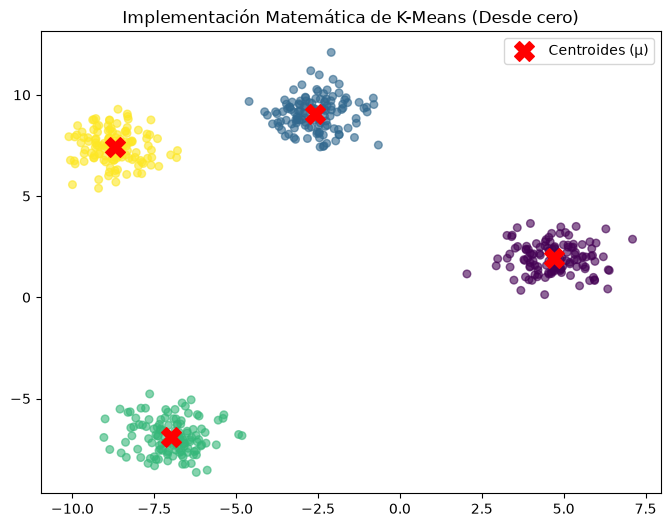

In [6]:
from sklearn.datasets import make_blobs

# Generamos datos sintéticos bidimensionales
X, _ = make_blobs(n_samples=500, centers=4, cluster_std=0.8, random_state=42)

# Instanciamos y entrenamos nuestro modelo puro
modelo = KMeansMatematico(k=4)
etiquetas = modelo.fit(X)

# Visualización de los resultados y los centroides finales
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap='viridis', alpha=0.6, s=30)
plt.scatter(modelo.centroids[:, 0], modelo.centroids[:, 1], 
            c='red', marker='X', s=200, label='Centroides (μ)')

plt.title("Implementación Matemática de K-Means (Desde cero)")
plt.legend()
plt.show()